
# Week 4: Absorption Ratio Analysis

**Owner:** Fatima Nasir

**Project:** Market Stress Early-Warning System for U.S. Equity Markets

**Focus:** Network Analysis

## Objective

Calculate the absorption ratio using historical stock returns.

The absorption ratio measures how much of the total variation in stock returns is explained by the largest principal components.

We will use this measure to investigate whether stocks become more interconnected during periods of market stress.


In [1]:

import pandas as pd
from pathlib import Path

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

processed_dir = ROOT / "data" / "processed"

for file in sorted(processed_dir.glob("*.parquet")):
    print(file.name)


daily_panel.parquet
returns_daily.parquet
returns_market.parquet
sp500_close.parquet
sp500_membership.parquet
sp500_volume.parquet
stress_labels_daily.parquet


In [ ]:

# Step 2: Inspect stock returns dataset

returns = pd.read_parquet(
    ROOT / "data" / "processed" / "returns_daily.parquet"
)

print("Shape:", returns.shape)
print("Columns:", returns.columns.tolist()[:15])
print("Index name:", returns.index.name)

display(returns.head(3))


Shape: (5490, 977)
Columns: ['A', 'AABA', 'AAL', 'AAP', 'AAPL', 'ABBV', 'ABC', 'ABI', 'ABKFQ', 'ABMD', 'ABNB', 'ABS', 'ABT', 'ACAS', 'ACGL']
Index name: Date


,A,AABA,AAL,AAP,AAPL,ABBV,ABC,ABI,ABKFQ,ABMD,...,XRAY,XRX,XTO,XYL,XYZ,YUM,ZBH,ZBRA,ZION,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2005-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-04,-0.026382,NaN,NaN,NaN,0.010270,NaN,-0.007911,NaN,NaN,NaN,...,NaN,-0.014732,NaN,NaN,NaN,-0.013242,-0.000378,NaN,-0.013652,NaN
2005-01-05,-0.000430,NaN,NaN,NaN,0.008759,NaN,-0.001907,NaN,NaN,NaN,...,NaN,-0.019737,NaN,NaN,NaN,-0.002381,-0.007813,NaN,-0.003611,NaN


In [3]:

# Step 3: Prepare returns for absorption ratio

import numpy as np

# Select the most recent 252 trading days
recent_returns = returns.tail(252).copy()

# Keep stocks with at least 90% available data
min_observations = int(252 * 0.90)

clean_returns = recent_returns.dropna(
    axis=1,
    thresh=min_observations
)

# Fill remaining missing values with each stock's mean
clean_returns = clean_returns.fillna(clean_returns.mean())

# Remove stocks with zero variance
clean_returns = clean_returns.loc[
    :, clean_returns.std() > 0
]

print("Original stocks:", returns.shape[1])
print("Stocks selected:", clean_returns.shape[1])
print("Trading days:", clean_returns.shape[0])
print("Missing values:", clean_returns.isna().sum().sum())

display(clean_returns.head(3))


Original stocks: 977
Stocks selected: 481
Trading days: 252
Missing values: 0


,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2025-10-28,-0.005048,0.000707,-0.002149,-0.008213,-0.004482,-0.014196,0.010288,0.005897,-0.015061,-0.009203,...,-0.011657,-0.036591,-0.010782,-0.007849,0.007363,0.000374,-0.013219,-0.019201,-0.116753,-0.014370
2025-10-29,-0.018169,0.002602,-0.010548,-0.011952,-0.017218,0.013338,-0.022104,-0.061265,-0.018007,-0.013850,...,-0.022746,0.000166,-0.001629,0.012344,0.016279,-0.045772,-0.013467,-0.014139,-0.012905,-0.010109
2025-10-30,0.001117,0.006303,0.013591,-0.001107,0.001929,0.009202,0.006055,0.004085,-0.009105,0.002809,...,0.013362,-0.009101,0.023842,-0.015114,-0.009284,-0.033852,-0.000934,-0.001504,-0.034716,0.001112


In [4]:

# Step 4: Calculate absorption ratio using PCA

from sklearn.decomposition import PCA

# Standardize stock returns
standardized_returns = (
    clean_returns - clean_returns.mean()
) / clean_returns.std()

# Fit PCA
pca = PCA(n_components=10)
pca.fit(standardized_returns)

# Calculate absorption ratio
absorption_ratio = pca.explained_variance_ratio_.sum()

print("Stocks analyzed:", clean_returns.shape[1])
print("Principal components:", 10)
print("Absorption ratio:", round(absorption_ratio, 4))
print("Percentage:", round(absorption_ratio * 100, 2), "%")


Stocks analyzed: 481
Principal components: 10
Absorption ratio: 0.4753
Percentage: 47.53 %


In [5]:

# Step 5: Calculate rolling absorption ratio

from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

window = 252
step = 21
n_components = 10

results = []

for end in range(window, len(returns) + 1, step):
    window_data = returns.iloc[end-window:end].copy()

    # Keep stocks with at least 90% available returns
    minimum = int(window * 0.90)
    window_data = window_data.dropna(
        axis=1, thresh=minimum
    )

    # Fill remaining missing values
    window_data = window_data.fillna(window_data.mean())

    # Remove stocks with zero variance
    window_data = window_data.loc[
        :, window_data.std() > 0
    ]

    if window_data.shape[1] < n_components:
        continue

    # Standardize returns
    standardized = (
        window_data - window_data.mean()
    ) / window_data.std()

    # Use randomized PCA for faster processing
    pca = PCA(
        n_components=n_components,
        svd_solver="randomized",
        random_state=42
    )

    pca.fit(standardized)

    results.append({
        "date": returns.index[end - 1],
        "absorption_ratio": pca.explained_variance_ratio_.sum(),
        "stocks_used": window_data.shape[1]
    })

absorption_df = pd.DataFrame(results)

print("Total observations:", len(absorption_df))
display(absorption_df.head())
display(absorption_df.tail())


Total observations: 250


,date,absorption_ratio,stocks_used
0,2005-12-30,0.445435,263
1,2006-02-01,0.440129,263
2,2006-03-03,0.440367,264
3,2006-04-03,0.434084,264
4,2006-05-03,0.417008,264


,date,absorption_ratio,stocks_used
245,2026-06-16,0.458732,479
246,2026-07-17,0.464529,477
247,2026-08-17,0.469580,478
248,2026-09-16,0.468809,478
249,2026-10-15,0.469566,480


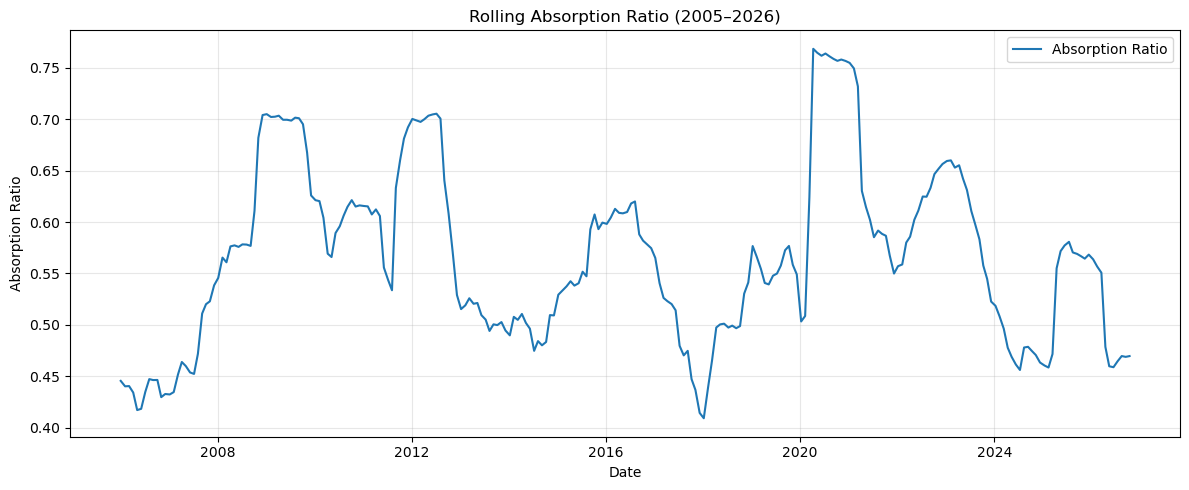

In [6]:

# Step 6: Visualize absorption ratio over time

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    absorption_df["date"],
    absorption_df["absorption_ratio"],
    label="Absorption Ratio"
)

plt.title("Rolling Absorption Ratio (2005–2026)")
plt.xlabel("Date")
plt.ylabel("Absorption Ratio")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:

# Step 7: Save absorption ratio feature

output_dir = ROOT / "data" / "processed" / "features"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "absorption_ratio_252d.csv"

absorption_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Total rows:", len(absorption_df))
print("File exists:", output_path.exists())


Saved: C:\Users\LATITUDE\Downloads\RGBFS-main\RGBFS-main\data\processed\features\absorption_ratio_252d.csv
Total rows: 250
File exists: True



## Results and Observations

The absorption ratio was calculated using historical S&P 500 stock returns from 2005 to 2026.

### Method
- Used a rolling window of 252 trading days.
- Calculated the ratio approximately every 21 trading days.
- Selected stocks with at least 90% available returns.
- Standardized returns and applied PCA using 10 components.
- Generated 250 observations.

### Findings
- The absorption ratio increased during the 2008 financial crisis.
- A large increase was also observed around the COVID-19 market shock in 2020.
- Another increase occurred around the 2022 market downturn.
- These patterns suggest that stock movements may become more concentrated during periods of market stress.

### Limitations
- The number of eligible stocks changes between windows.
- Missing returns were filled using each stock's mean.
- Only 10 principal components were used.
- The feature is calculated approximately monthly rather than daily.
- The observed patterns do not prove that the absorption ratio can predict market stress.

### Conclusion
The absorption ratio provides a useful measure of common stock-market movements. It may contribute to the project's market stress early-warning system when combined with other indicators.

The calculated feature was saved to:
`data/processed/features/absorption_ratio_252d.csv`
